In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
df = pd.read_csv("https://raw.githubusercontent.com/adi1234-5/dataset/refs/heads/main/Retail%20Sales%20Transactions%202024-2025.csv", header=1)

In [ ]:
df.head()

,Order_ID,Customer_Name,Gender,Category,Product,Quantity,Unit_Price,Discount,Order_Date,Sales_Channel,Region,Phone,Product_Name_Duplicate
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1000.0,Riya,Female,Clothing,Jacket,1.0,199.0,10.0,01-25-2024,Wholesale,NaN,9876543210,Jacket
3,1001.0,Sam,Female,GROCERIES,Rice,4.0,499.0,0.0,10-26-2024,Retail,NaN,NaN,Rice
4,1002.0,Sam,NaN,electronics,Tablet,NaN,499.0,NaN,01-02-2024,Wholesale,South,9876543210,Tablet


In [ ]:
df.tail()

,Order_ID,Customer_Name,Gender,Category,Product,Quantity,Unit_Price,Discount,Order_Date,Sales_Channel,Region,Phone,Product_Name_Duplicate
497,1495.0,Asha,NaN,Electronics,Tablet,NaN,1500.0,5.0,10-06-2024,Wholesale,South,91-9988776655,Tablet
498,1496.0,Chen,Male,Groceries,Rice,4.0,499.0,10.0,02-27-2024,Wholesale,South,NaN,Rice
499,1497.0,Riya,Male,Furniture,Desk,2.0,NaN,10.0,12-09-2024,Wholesale,NaN,NaN,Desk
500,1498.0,Maria,NaN,electronics,Laptop,NaN,NaN,NaN,01-31-2025,Online,West,NaN,Laptop
501,1499.0,Wei,NaN,electronics,Tablet,NaN,NaN,0.0,09-11-2024,Online,NaN,91-9988776655,Tablet


In [ ]:
df.shape

(502, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                500 non-null    float64
 1   Customer_Name           500 non-null    object 
 2   Gender                  335 non-null    object 
 3   Category                500 non-null    object 
 4   Product                 500 non-null    object 
 5   Quantity                350 non-null    float64
 6   Unit_Price              340 non-null    float64
 7   Discount                317 non-null    float64
 8   Order_Date              500 non-null    object 
 9   Sales_Channel           382 non-null    object 
 10  Region                  401 non-null    object 
 11  Phone                   297 non-null    object 
 12  Product_Name_Duplicate  500 non-null    object 
dtypes: float64(4), object(9)
memory usage: 51.1+ KB


In [ ]:
df.describe()

,Order_ID,Quantity,Unit_Price,Discount
count,500.000000,350.000000,340.000000,317.000000
mean,1249.500000,2.954286,793.955882,7.287066
std,144.481833,1.405340,493.708005,5.672183
min,1000.000000,1.000000,199.000000,0.000000
25%,1124.750000,2.000000,499.000000,0.000000
50%,1249.500000,3.000000,499.000000,10.000000
75%,1374.250000,4.000000,1124.250000,10.000000
max,1499.000000,5.000000,1500.000000,15.000000


In [ ]:
print("Categorical Summary Statistics:")
print(df.describe(include='object'))

Categorical Summary Statistics:
       Customer_Name Gender   Category Product  Order_Date Sales_Channel  \
count            500    335        500     500         500           382   
unique            10      2          7      12         308             3   
top            Emily   Male  GROCERIES    Rice  02-27-2024        Retail   
freq              63    181         82      55           7           137   

       Region          Phone Product_Name_Duplicate  
count     401            297                    500  
unique      4              3                     12  
top      East  91-9988776655                   Rice  
freq      105            104                     55  


In [ ]:
# Additional Statistical Analysis

print("Median:")
print(df.median(numeric_only=True))

print("\nVariance:")
print(df.var(numeric_only=True))

print("\nStandard Deviation:")
print(df.std(numeric_only=True))

print("\nSkewness:")
print(df.skew(numeric_only=True))

print("\nKurtosis:")
print(df.kurt(numeric_only=True))

Median:
Order_ID      1249.5
Quantity         3.0
Unit_Price     499.0
Discount        10.0
dtype: float64

Variance:
Order_ID       20875.000000
Quantity           1.974982
Unit_Price    243747.593918
Discount          32.173661
dtype: float64

Standard Deviation:
Order_ID      144.481833
Quantity        1.405340
Unit_Price    493.708005
Discount        5.672183
dtype: float64

Skewness:
Order_ID      0.000000
Quantity      0.031732
Unit_Price    0.273739
Discount      0.014411
dtype: float64

Kurtosis:
Order_ID     -1.200000
Quantity     -1.274999
Unit_Price   -1.402978
Discount     -1.399734
dtype: float64


In [ ]:
df.isnull().sum()     #Check missing values

,0
Order_ID,2
Customer_Name,2
Gender,167
Category,2
Product,2
Quantity,152
Unit_Price,162
Discount,185
Order_Date,2
Sales_Channel,120


In [ ]:
df = df.dropna(how='all')   #Remove empty rows

In [ ]:
# Handle Missing Values

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())


categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
Order_ID                  0
Customer_Name             0
Gender                    0
Category                  0
Product                   0
Quantity                  0
Unit_Price                0
Discount                  0
Order_Date                0
Sales_Channel             0
Region                    0
Phone                     0
Product_Name_Duplicate    0
dtype: int64


In [ ]:
df.duplicated().sum() #Check duplicate rows

np.int64(0)

In [ ]:
df = df.drop_duplicates()   #Remove duplicate rows

In [ ]:
df.describe()

,Order_ID,Quantity,Unit_Price,Discount
count,500.000000,500.000000,500.000000,500.00000
mean,1249.500000,2.968000,699.570000,8.28000
std,144.481833,1.175474,429.605595,4.69955
min,1000.000000,1.000000,199.000000,0.00000
25%,1124.750000,2.000000,499.000000,5.00000
50%,1249.500000,3.000000,499.000000,10.00000
75%,1374.250000,4.000000,999.000000,10.00000
max,1499.000000,5.000000,1500.000000,15.00000


In [ ]:
df['Category'].value_counts()   #Check different categories

,count
Category,
GROCERIES,82
Groceries,80
electronics,76
CLOTHING,72
Electronics,67
Furniture,64
Clothing,59


In [ ]:
df['Region'].value_counts()    #Check different regions

,count
Region,
East,204
North,105
West,98
South,93


In [ ]:
df['Sales_Channel'].value_counts()     #sales channels count

,count
Sales_Channel,
Retail,255
Wholesale,128
Online,117


In [ ]:
df['Sales'] = df['Quantity'] * df['Unit_Price']  # total sales

In [ ]:
df['Sales'].sum()

np.float64(1025272.0)

In [ ]:
df['Sales'].max()  # highest sales

7500.0

In [ ]:
df['Sales'].mean()    # average sales

np.float64(2050.544)

In [ ]:
df['Quantity'].sum()    # quantity sold

np.float64(1484.0)

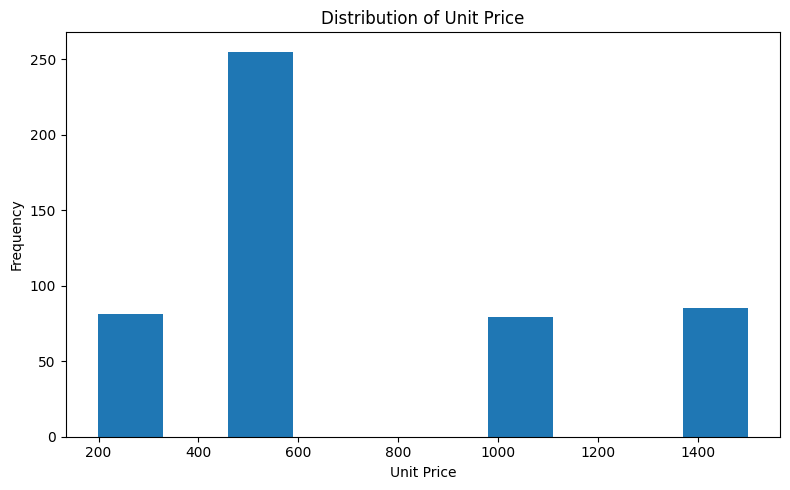

Insight:
The histogram shows how frequently different unit price ranges occur in the dataset.


In [ ]:
# Histogram - Unit Price Distribution

plt.figure(figsize=(8,5))

plt.hist(df['Unit_Price'], bins=10)

plt.title('Distribution of Unit Price')
plt.xlabel('Unit Price')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

print("Insight:")
print("The histogram shows how frequently different unit price ranges occur in the dataset.")

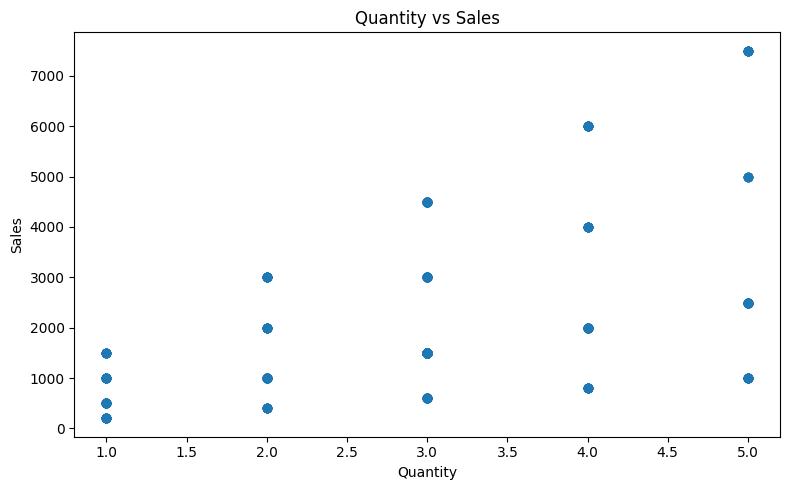

Insight:
The scatter plot shows the relationship between quantity sold and total sales.


In [ ]:
# Scatter Plot - Quantity vs Sales

plt.figure(figsize=(8,5))

plt.scatter(
    df['Quantity'],
    df['Sales']
)

plt.title('Quantity vs Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')

plt.tight_layout()
plt.show()

print("Insight:")
print("The scatter plot shows the relationship between quantity sold and total sales.")

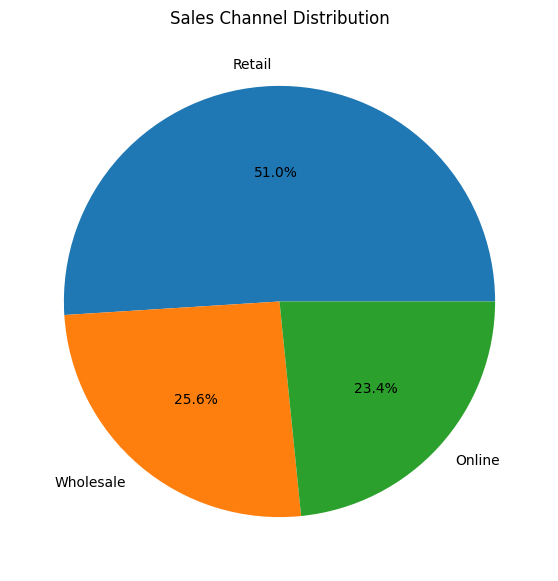

Insight:
The pie chart shows the proportion of transactions across different sales channels.


In [ ]:
# Pie Chart - Sales Channel Distribution

channel_counts = df['Sales_Channel'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    channel_counts,
    labels=channel_counts.index,
    autopct='%1.1f%%'
)

plt.title('Sales Channel Distribution')

plt.show()

print("Insight:")
print("The pie chart shows the proportion of transactions across different sales channels.")

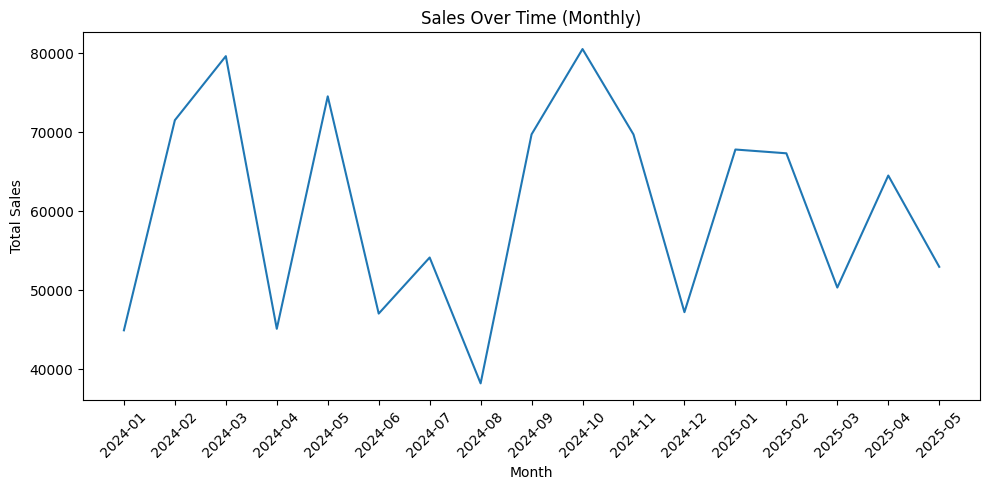

Note:
The line plot shows how total sales vary over different order dates.


In [ ]:
# Line Plot - Sales Over Time

# 1. Ensure Order_Date is in datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# 2. Extract Year-Month for cleaner grouping
df['Year_Month'] = df['Order_Date'].dt.to_period('M')

# 3. Group by the new monthly column
sales_over_time = (
    df.groupby('Year_Month')['Sales']
    .sum()
    .sort_index()
)

# Convert period index to string so matplotlib plots it nicely
sales_over_time.index = sales_over_time.index.astype(str)

plt.figure(figsize=(10, 5))
plt.plot(
    sales_over_time.index,
    sales_over_time.values
)
plt.title('Sales Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


print("Note:")
print("The line plot shows how total sales vary over different order dates.")

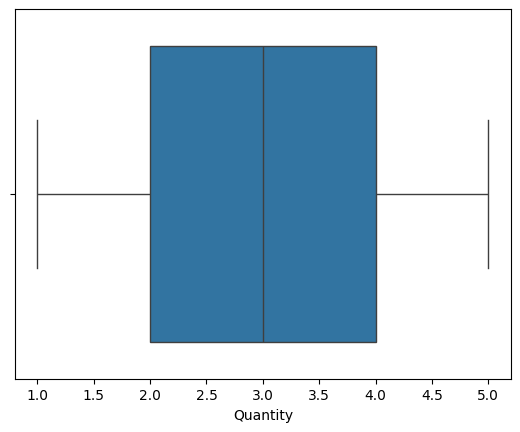

In [ ]:
# Outliers

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Quantity'])

plt.show()

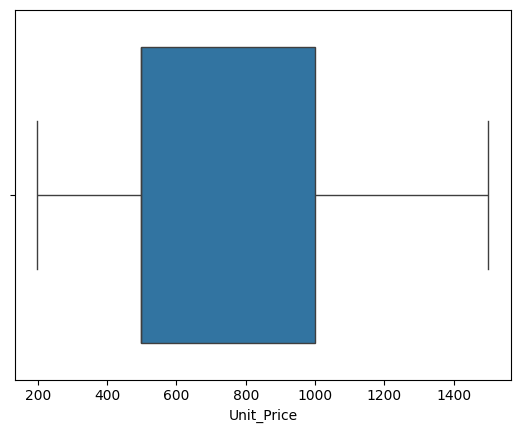

In [ ]:
sns.boxplot(x=df['Unit_Price'])
plt.show()

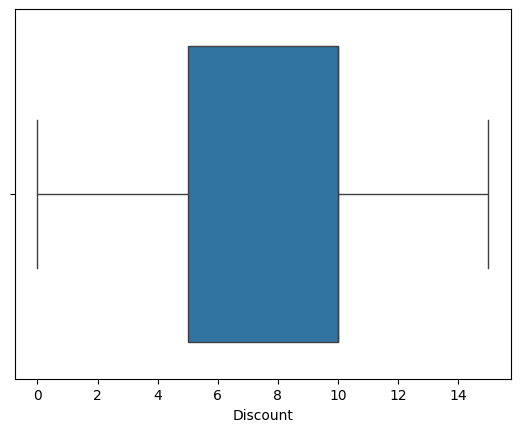

In [ ]:
sns.boxplot(x=df['Discount'])
plt.show()

In [ ]:
df[['Quantity', 'Unit_Price', 'Discount']].describe()

,Quantity,Unit_Price,Discount
count,500.000000,500.000000,500.00000
mean,2.968000,699.570000,8.28000
std,1.175474,429.605595,4.69955
min,1.000000,199.000000,0.00000
25%,2.000000,499.000000,5.00000
50%,3.000000,499.000000,10.00000
75%,4.000000,999.000000,10.00000
max,5.000000,1500.000000,15.00000


In [ ]:

df['Sales'] = df['Quantity'] * df['Unit_Price']

Sales by Category:
Category
 CLOTHING      132303.0
Clothing       113162.0
Electronics    130728.0
Furniture      141754.0
GROCERIES      175414.0
Groceries      181996.0
electronics    149915.0
Name: Sales, dtype: float64


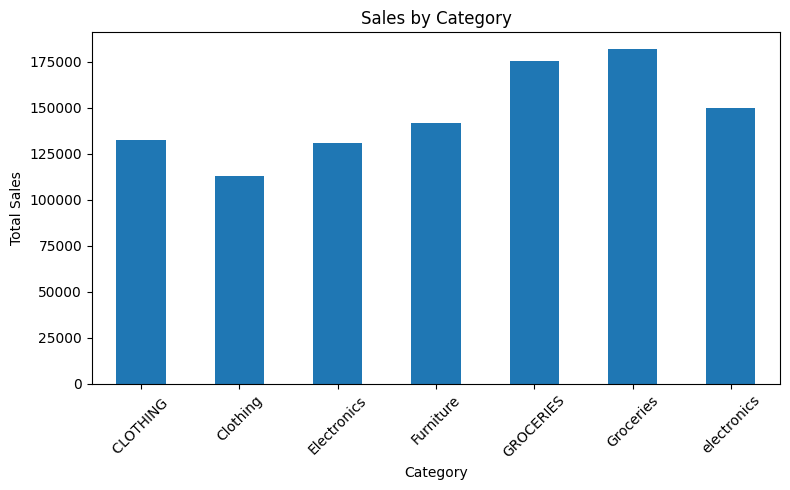

Insight:
Sales contribution varies across different product categories.


In [ ]:
# Sales by Category

sales_by_category = df.groupby('Category')['Sales'].sum()

print("Sales by Category:")
print(sales_by_category)

sales_by_category.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Insight:")
print("Sales contribution varies across different product categories.")

In [ ]:
# Correlation
df.select_dtypes(include='number').corr()

,Order_ID,Quantity,Unit_Price,Discount,Sales
Order_ID,1.000000,0.052391,0.063735,0.013045,0.067553
Quantity,0.052391,1.000000,-0.051152,0.077081,0.460272
Unit_Price,0.063735,-0.051152,1.000000,0.075348,0.802269
Discount,0.013045,0.077081,0.075348,1.000000,0.108446
Sales,0.067553,0.460272,0.802269,0.108446,1.000000


Feature engineering

In [ ]:
df['Sales'] = df['Quantity'] * df['Unit_Price']

In [ ]:
df['Discount_Amount'] = df['Sales'] * df['Discount'] / 100

In [ ]:
df['Final_Sales'] = df['Sales'] - df['Discount_Amount']

In [ ]:
# Date Feature Engineering

df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    errors='coerce'
)

df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Day'] = df['Order_Date'].dt.day
df['Order_DayOfWeek'] = df['Order_Date'].dt.dayofweek

print("After Date Feature Engineering:")
print(df[['Order_Date',
          'Order_Year',
          'Order_Month',
          'Order_Day',
          'Order_DayOfWeek']].head())

After Date Feature Engineering:
  Order_Date  Order_Year  Order_Month  Order_Day  Order_DayOfWeek
2 2024-01-25        2024            1         25                3
3 2024-10-26        2024           10         26                5
4 2024-01-02        2024            1          2                1
5 2024-03-27        2024            3         27                2
6 2024-08-30        2024            8         30                4


In [ ]:
df[['Quantity', 'Unit_Price', 'Discount', 'Sales', 'Final_Sales']].head()

,Quantity,Unit_Price,Discount,Sales,Final_Sales
2,1.0,199.0,10.0,199.0,179.10
3,4.0,499.0,0.0,1996.0,1996.00
4,3.0,499.0,10.0,1497.0,1347.30
5,3.0,499.0,5.0,1497.0,1422.15
6,5.0,499.0,10.0,2495.0,2245.50


EDA/graphs


In [ ]:
# IQR outlier detection
outlier_cols = ["Quantity", "Unit_Price", "Discount"]

iqr_summary = []

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)
    iqr_summary.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outliers": int(mask.sum())
    })

iqr_summary = pd.DataFrame(iqr_summary)
print(iqr_summary)


       Column     Q1     Q3    IQR  Lower_Bound  Upper_Bound  Outliers
0    Quantity    2.0    4.0    2.0         -1.0          7.0         0
1  Unit_Price  499.0  999.0  500.0       -251.0       1749.0         0
2    Discount    5.0   10.0    5.0         -2.5         17.5         0


In [ ]:
from scipy.stats import zscore
import numpy as np

zscore_summary = []

for col in outlier_cols:
    z = zscore(df[col], nan_policy="omit")
    mask = np.abs(z) > 3

    zscore_summary.append({
        "Column": col,
        "Outliers_Z_gt_3": int(mask.sum())
    })

    df[f"{col}_ZScore"] = z

zscore_summary = pd.DataFrame(zscore_summary)
print(zscore_summary)

       Column  Outliers_Z_gt_3
0    Quantity                0
1  Unit_Price                0
2    Discount                0


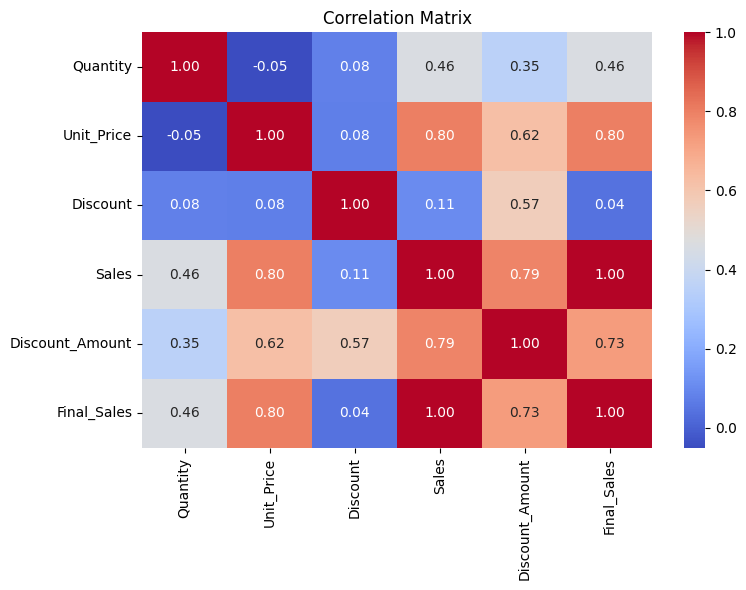

In [ ]:
corr_cols = ["Quantity", "Unit_Price", "Discount", "Sales",
             "Discount_Amount", "Final_Sales"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [ ]:
# Label Encoding

label_encoder = LabelEncoder()

df['Gender_Label'] = label_encoder.fit_transform(
    df['Gender'].astype(str)
)

print("After Label Encoding:")
print(
    df[['Gender', 'Gender_Label']].head()
)

After Label Encoding:
   Gender  Gender_Label
2  Female             0
3  Female             0
4    Male             1
5    Male             1
6  Female             0


In [ ]:
# One-Hot Encoding

onehot = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

encoded = onehot.fit_transform(
    df[['Sales_Channel']]
)

encoded_df = pd.DataFrame(
    encoded,
    columns=onehot.get_feature_names_out(
        ['Sales_Channel']
    ),
    index=df.index
)

print("One-Hot Encoded Columns:")
print(encoded_df.head())

# Add encoded columns to dataset
df = pd.concat(
    [df, encoded_df],
    axis=1
)

print("Dataset After One-Hot Encoding:")
print(df.head())

One-Hot Encoded Columns:
   Sales_Channel_Online  Sales_Channel_Retail  Sales_Channel_Wholesale
2                   0.0                   0.0                      1.0
3                   0.0                   1.0                      0.0
4                   0.0                   0.0                      1.0
5                   0.0                   1.0                      0.0
6                   0.0                   1.0                      0.0
Dataset After One-Hot Encoding:
   Order_ID Customer_Name  Gender     Category Product  Quantity  Unit_Price  \
2    1000.0          Riya  Female     Clothing  Jacket       1.0       199.0   
3    1001.0           Sam  Female    GROCERIES    Rice       4.0       499.0   
4    1002.0           Sam    Male  electronics  Tablet       3.0       499.0   
5    1003.0          John    Male  Electronics  Mobile       3.0       499.0   
6    1004.0          John  Female    CLOTHING    Shirt       5.0       499.0   

   Discount Order_Date Sales_Channel

In [ ]:
# Standardization using StandardScaler

features = df[
    [
        'Quantity',
        'Unit_Price',
        'Discount',
        'Sales',
        'Discount_Amount',
        'Final_Sales'
    ]
]

standard_scaler = StandardScaler()

standardized = standard_scaler.fit_transform(
    features
)

standardized_df = pd.DataFrame(
    standardized,
    columns=features.columns,
    index=df.index
)

print("Standardized Features:")
print(standardized_df.head())

Standardized Features:
   Quantity  Unit_Price  Discount     Sales  Discount_Amount  Final_Sales
2 -1.675895   -1.166352  0.366359 -1.192877        -0.826006    -1.204040
3  0.878823   -0.467338 -1.763635 -0.035141        -0.930181     0.087539
4  0.027250   -0.467338  0.366359 -0.356627        -0.146513    -0.373602
5  0.027250   -0.467338 -0.698638 -0.356627        -0.538347    -0.320394
6  1.730395   -0.467338  0.366359  0.286345         0.375932     0.264901


In [ ]:
# Normalization using MinMaxScaler

minmax_scaler = MinMaxScaler()

normalized = minmax_scaler.fit_transform(
    features
)

normalized_df = pd.DataFrame(
    normalized,
    columns=features.columns,
    index=df.index
)

print("Normalized Features:")
print(normalized_df.head())

Normalized Features:
   Quantity  Unit_Price  Discount     Sales  Discount_Amount  Final_Sales
2      0.00    0.000000  0.666667  0.000000         0.017689     0.001357
3      0.75    0.230592  0.000000  0.246131         0.000000     0.249200
4      0.50    0.230592  0.666667  0.177784         0.133067     0.160711
5      0.50    0.230592  0.333333  0.177784         0.066533     0.170922
6      1.00    0.230592  0.666667  0.314477         0.221778     0.283235


In [ ]:
# Final summary
print("Final dataset shape:", df.shape)
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Discount Amount:", round(df["Discount_Amount"].sum(), 2))
print("Total Final Sales:", round(df["Final_Sales"].sum(), 2))
print("Total Quantity Sold:", round(df["Quantity"].sum(), 2))

Final dataset shape: (500, 28)
Total Sales: 1025272.0
Total Discount Amount: 88843.85
Total Final Sales: 936428.15
Total Quantity Sold: 1484.0


Index(['Order_ID', 'Customer_Name', 'Gender', 'Category', 'Product',
       'Quantity', 'Unit_Price', 'Discount', 'Order_Date', 'Sales_Channel',
       'Region', 'Phone', 'Product_Name_Duplicate', 'Sales', 'Year_Month',
       'Discount_Amount', 'Final_Sales', 'Order_Year', 'Order_Month',
       'Order_Day', 'Order_DayOfWeek', 'Quantity_ZScore', 'Unit_Price_ZScore',
       'Discount_ZScore', 'Gender_Label', 'Sales_Channel_Online',
       'Sales_Channel_Retail', 'Sales_Channel_Wholesale'],
      dtype='object')
   Quantity
2       1.0
3       4.0
4       3.0
5       3.0
6       5.0
2    199.0
3    499.0
4    499.0
5    499.0
6    499.0
Name: Unit_Price, dtype: float64
Intercept (b0): 755.0563374561995
Coefficient (b1): -18.694857633490383
First 10 predicted values:
[736.36147982 680.27690692 698.97176456 698.97176456 661.58204929
 736.36147982 717.66662219 698.97176456 680.27690692 698.97176456]
Mean Absolute Error is: 364.9899189659574
Mean Squared Error is: 183709.89615697443
Root Mea

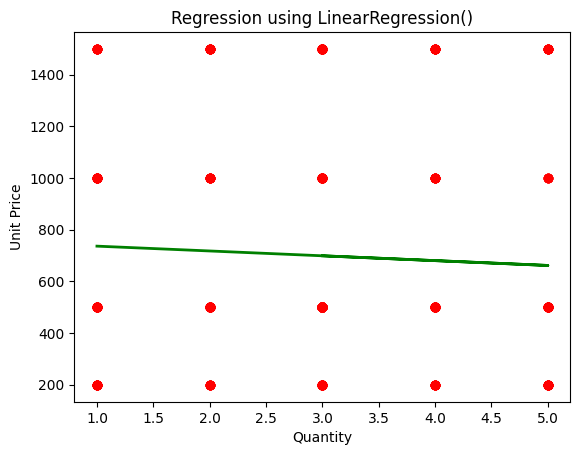

In [ ]:
#linear regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import pandas as pd
print(df.columns)

#reshaping x and y
X = df[["Quantity"]]
Y = df["Unit_Price"]
print(X.head())
print(Y.head())

#using linear regression
model = LinearRegression()
model.fit(X, Y) #HERE X is x_TRAIN AND Y_TRAIN  //TRAINED DATASET

#intercept
print("Intercept (b0):", model.intercept_)

#coeffient
print("Coefficient (b1):", model.coef_[0])

#prediction
y_pred2 = model.predict(X)   #X_tests
print("First 10 predicted values:")
print(y_pred2[:10])

#mean absolute error
MAE = mean_absolute_error(Y, y_pred2)
print("Mean Absolute Error is:", MAE)

#mean squared error
MSE = mean_squared_error(Y, y_pred2)
print("Mean Squared Error is:", MSE)

#root mean squared erro
RMSE = np.sqrt(MSE)
print("Root Mean Squared Error is:", RMSE)

#accuracy in regression
r2pred2 = model.score(X, Y)
print("R2 is : ",r2pred2)

plt.scatter(X, Y, color="red")
plt.plot(X, y_pred2, color="green", linewidth=2)
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.title("Regression using LinearRegression()")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Multiple Linear Regression

X_multi = df[['Quantity', 'Unit_Price', 'Discount']]
Y_multi = df['Final_Sales']

X_train_multi, X_test_multi, Y_train_multi, Y_test_multi = train_test_split(
    X_multi, Y_multi, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()

multiple_model.fit(X_train_multi, Y_train_multi)

Y_pred_multi = multiple_model.predict(X_test_multi)

print("Multiple Linear Regression")
print("--------------------------")
print("Intercept:", multiple_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X_multi.columns, multiple_model.coef_):
    print(feature, ":", coefficient)

mae_multi = mean_absolute_error(Y_test_multi, Y_pred_multi)
mse_multi = mean_squared_error(Y_test_multi, Y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(Y_test_multi, Y_pred_multi)

print("\nModel Evaluation")
print("--------------------------")
print("MAE :", mae_multi)
print("MSE :", mse_multi)
print("RMSE:", rmse_multi)
print("R²  :", r2_multi)

Multiple Linear Regression
--------------------------
Intercept: -1643.7502498010995

Coefficients:
Quantity : 594.4905879383293
Unit_Price : 2.7420765283210295
Discount : -20.17779314976928

Model Evaluation
--------------------------
MAE : 360.24985194964364
MSE : 327460.54603767744
RMSE: 572.2416849878008
R²  : 0.8621820928858963


In [ ]:
# Polynomial Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(X, Y)

y_pred_poly = poly_model.predict(X)

# Evaluation

mae_poly = mean_absolute_error(Y, y_pred_poly)
print("MAE for Polynomial Regression is : ", mae_poly)

mse_poly = mean_squared_error(Y, y_pred_poly)
print("MSE for Polynomial Regression is : ", mse_poly)

rmse_poly = np.sqrt(mse_poly)
print("RMSE for Polynomial Regression is : ", rmse_poly)

r2_poly = r2_score(Y, y_pred_poly)
print("R2 for Polynomial Regression is : ", r2_poly)


# Regression Comparison

comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],
    'MAE': [
        MAE,
        mae_multi,
        mae_poly
    ],
    'MSE': [
        MSE,
        mse_multi,
        mse_poly
    ],
    'RMSE': [
        RMSE,
        rmse_multi,
        rmse_poly
    ],
    'R2 Score': [
        r2pred2,
        r2_multi,
        r2_poly
    ]
})

print("Regression Model Comparison:")
display(comparison)

MAE for Polynomial Regression is :  364.5119773165043
MSE for Polynomial Regression is :  182841.64295201498
RMSE for Polynomial Regression is :  427.5998631337655
R2 for Polynomial Regression is :  0.007330412197412706
Regression Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,364.989919,183709.896157,428.613924,0.002617
1,Multiple Linear Regression,360.249852,327460.546038,572.241685,0.862182
2,Polynomial Regression,364.511977,182841.642952,427.599863,0.007330


In [ ]:
# Logistic Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
# Create binary target variable

median_sales = df['Final_Sales'].median()

df['Sales_Class'] = np.where(
    df['Final_Sales'] >= median_sales,
    1,
    0
)

print("Median Final Sales:", median_sales)

print("\nSales Class Distribution:")
print(df['Sales_Class'].value_counts())

print("\nSales Class:")
print("0 = Low Sales")
print("1 = High Sales")

Median Final Sales: 1348.65

Sales Class Distribution:
Sales_Class
0    250
1    250
Name: count, dtype: int64

Sales Class:
0 = Low Sales
1 = High Sales


In [ ]:
# Select features and target

X_log = df[
    [
        'Quantity',
        'Unit_Price',
        'Discount'
    ]
]

Y_log = df['Sales_Class']

print("Features:")
print(X_log.head())

print("\nTarget:")
print(Y_log.head())

Features:
   Quantity  Unit_Price  Discount
2       1.0       199.0      10.0
3       4.0       499.0       0.0
4       3.0       499.0      10.0
5       3.0       499.0       5.0
6       5.0       499.0      10.0

Target:
2    0
3    1
4    0
5    1
6    1
Name: Sales_Class, dtype: int64


In [ ]:
# Split dataset into training and testing sets

X_train_log, X_test_log, Y_train_log, Y_test_log = train_test_split(
    X_log,
    Y_log,
    test_size=0.2,
    random_state=42,
    stratify=Y_log
)

print("Training data shape:", X_train_log.shape)
print("Testing data shape:", X_test_log.shape)

Training data shape: (400, 3)
Testing data shape: (100, 3)


In [ ]:
# Create and train Logistic Regression model

log_model = LogisticRegression()

log_model.fit(
    X_train_log,
    Y_train_log
)

print("Logistic Regression Model trained successfully.")

Logistic Regression Model trained successfully.


In [ ]:
# Display intercept and coefficients

print("Intercept:", log_model.intercept_[0])

print("\nCoefficients:")

for feature, coefficient in zip(
    X_log.columns,
    log_model.coef_[0]
):
    print(feature, ":", coefficient)

Intercept: -15.27567781783011

Coefficients:
Quantity : 3.0866670642410297
Unit_Price : 0.01428254492226209
Discount : -0.3350464794209701


In [ ]:
# Make predictions

Y_pred_log = log_model.predict(X_test_log)

print("First 10 Actual Values:")
print(Y_test_log.values[:10])

print("\nFirst 10 Predicted Values:")
print(Y_pred_log[:10])

First 10 Actual Values:
[1 0 0 1 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 0 1 1 1 1 0 0 0]


In [ ]:
# Evaluate Logistic Regression model

accuracy_log = accuracy_score(
    Y_test_log,
    Y_pred_log
)

precision_log = precision_score(
    Y_test_log,
    Y_pred_log
)

recall_log = recall_score(
    Y_test_log,
    Y_pred_log
)

f1_log = f1_score(
    Y_test_log,
    Y_pred_log
)

print("Logistic Regression Evaluation")
print("------------------------------")

print("Accuracy :", accuracy_log)
print("Precision:", precision_log)
print("Recall   :", recall_log)
print("F1 Score :", f1_log)

Logistic Regression Evaluation
------------------------------
Accuracy : 0.89
Precision: 0.975609756097561
Recall   : 0.8
F1 Score : 0.8791208791208791


Confusion Matrix:
[[49  1]
 [10 40]]


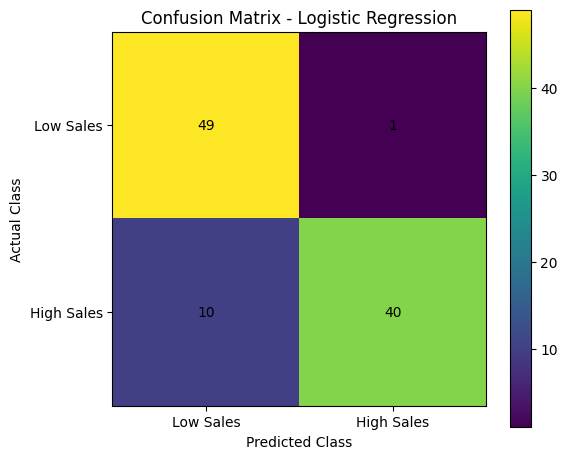

In [ ]:
# Confusion Matrix

cm_log = confusion_matrix(
    Y_test_log,
    Y_pred_log
)

print("Confusion Matrix:")
print(cm_log)

plt.figure(figsize=(6,5))

plt.imshow(cm_log)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Low Sales", "High Sales"])
plt.yticks([0, 1], ["Low Sales", "High Sales"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm_log[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# Classification Report

print("Classification Report:")
print(
    classification_report(
        Y_test_log,
        Y_pred_log,
        target_names=["Low Sales", "High Sales"]
    )
)

Classification Report:
              precision    recall  f1-score   support

   Low Sales       0.83      0.98      0.90        50
  High Sales       0.98      0.80      0.88        50

    accuracy                           0.89       100
   macro avg       0.90      0.89      0.89       100
weighted avg       0.90      0.89      0.89       100



In [ ]:
# Logistic Regression Results

log_results = {
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Logistic Regression': [
        accuracy_log,
        precision_log,
        recall_log,
        f1_log
    ]
}
log_results_df = pd.DataFrame(log_results)

print("--- Logistic Regression Results ---")
display(log_results_df)

--- Logistic Regression Results ---


,Metric,Logistic Regression
0,Accuracy,0.890000
1,Precision,0.975610
2,Recall,0.800000
3,F1 Score,0.879121


In [ ]:
# Prediction probabilities

Y_probability = log_model.predict_proba(X_test_log)

probability_df = pd.DataFrame({
    'Actual_Class': Y_test_log.values,
    'Predicted_Class': Y_pred_log,
    'Low_Sales_Probability': Y_probability[:, 0],
    'High_Sales_Probability': Y_probability[:, 1]
})

print("Prediction Probabilities:")
display(probability_df.head(10))

Prediction Probabilities:


,Actual_Class,Predicted_Class,Low_Sales_Probability,High_Sales_Probability
0,1,0,0.637359,0.362641
1,0,0,0.993707,0.006293
2,0,0,0.903711,0.096289
3,1,1,0.007376,0.992624
4,1,1,0.000001,0.999999
5,1,1,0.299954,0.700046
6,1,1,0.000686,0.999314
7,0,0,0.878185,0.121815
8,0,0,0.993707,0.006293
9,0,0,0.999778,0.000222


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Select features and target for KNN (using the same as Logistic Regression for consistency)
X_knn = df[['Quantity', 'Unit_Price', 'Discount']]
Y_knn = df['Sales_Class']

# Split the dataset into training and testing sets
X_train_knn, X_test_knn, y_train, y_test = train_test_split(
    X_knn, Y_knn, test_size=0.2, random_state=42, stratify=Y_knn
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_knn)
X_test_scaled = scaler.transform(X_test_knn)

#K-NEAREST NEIGHBORS (KNN)

knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Model trained and predictions made.")

KNN Model trained and predictions made.


In [ ]:
def evaluate_model(model_name, y_true, y_pred):

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print("Accuracy  :", round(accuracy, 4))
    print("Precision :", round(precision, 4))
    print("Recall    :", round(recall, 4))
    print("F1-Score  :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Low Sales", "High Sales"]
    ))

    print("Confusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(cm)

    return accuracy, precision, recall, f1

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.tree import DecisionTreeClassifier

# Decision Tree
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_scaled, y_train) # Train on scaled data
y_pred_tree = tree_model.predict(X_test_scaled)

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    Y_pred_log
)

tree_results = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_tree
)

knn_results = evaluate_model(
    "K-Nearest Neighbors (KNN)",
    y_test,
    y_pred_knn
)


Logistic Regression
Accuracy  : 0.89
Precision : 0.9756
Recall    : 0.8
F1-Score  : 0.8791

Classification Report:
              precision    recall  f1-score   support

   Low Sales       0.83      0.98      0.90        50
  High Sales       0.98      0.80      0.88        50

    accuracy                           0.89       100
   macro avg       0.90      0.89      0.89       100
weighted avg       0.90      0.89      0.89       100

Confusion Matrix:
[[49  1]
 [10 40]]

Decision Tree
Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1-Score  : 1.0

Classification Report:
              precision    recall  f1-score   support

   Low Sales       1.00      1.00      1.00        50
  High Sales       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

Confusion Matrix:
[[50  0]
 [ 0 50]]

K-Nearest Neighbors (KNN)
Accuracy  : 0.98
Precision

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],

    "Accuracy": [
        logistic_results[0],
        tree_results[0],
        knn_results[0]
    ],

    "Precision": [
        logistic_results[1],
        tree_results[1],
        knn_results[1]
    ],

    "Recall": [
        logistic_results[2],
        tree_results[2],
        knn_results[2]
    ],

    "F1-Score": [
        logistic_results[3],
        tree_results[3],
        knn_results[3]
    ]
})

print("\n\nMODEL COMPARISON")
print("=" * 70)
print(results.round(4))



MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression      0.89     0.9756     0.8    0.8791
1        Decision Tree      1.00     1.0000     1.0    1.0000
2                  KNN      0.98     0.9615     1.0    0.9804


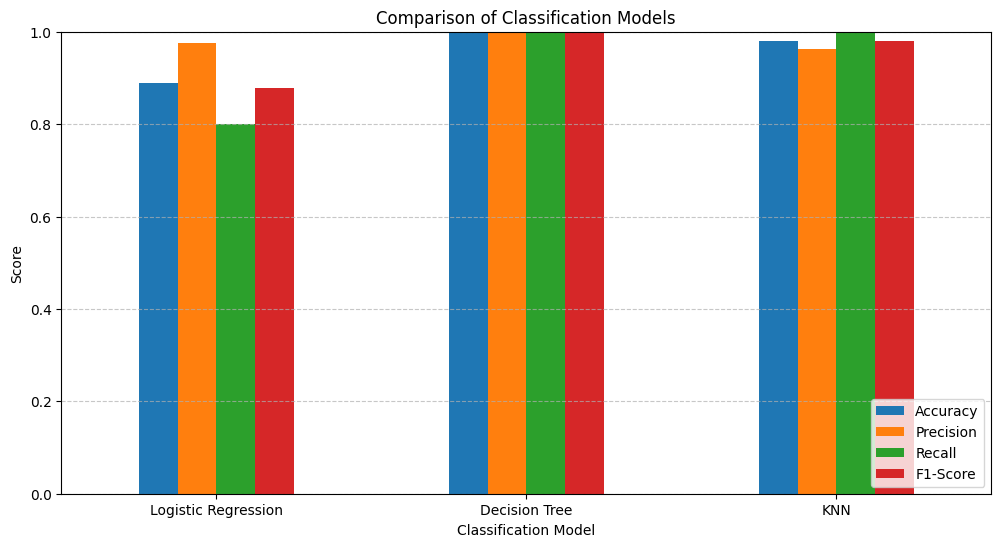

In [ ]:

results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


In [ ]:
# Save dataset
df.to_csv("cleaned_retail_sales.csv", index=False)

print("Files saved successfully.")

Files saved successfully.


### Final Findings and Observations

1. The dataset contains 500 retail sales transactions with information about customers, products, quantity, price, discount, sales channel, region, and sales.

2. Data preprocessing was performed by handling missing values and duplicate records, followed by feature engineering of date-related attributes such as year, month, day, and day of the week.

3. Outlier analysis was performed using both the IQR method and Z-score analysis. This helped identify unusually high or low values in important numerical features.

4. Categorical variables were converted into numerical form using Label Encoding and One-Hot Encoding where appropriate.

5. Standardization and normalization were applied to numerical features to bring them to suitable scales for machine learning models.

6. Simple Linear Regression showed a very weak relationship between Quantity and Unit Price, as indicated by its low R² score.

7. Multiple Linear Regression produced a substantially higher R² score, indicating that Quantity, Unit Price, and Discount together explain a significant portion of the variation in Final Sales.

8. Polynomial Regression was also evaluated. For the selected variables, it provided only a small improvement over Simple Linear Regression.

9. Logistic Regression was used to classify transactions into Low Sales and High Sales based on the median Final Sales value. The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

10. Overall, the analysis demonstrates how data preprocessing, exploratory analysis, regression, and classification techniques can be applied to understand and analyze retail sales transactions.


#***report on this project***

explanation as analysis part there

diagram displayed analysis - kaha plot use karna hai ,kyu use karna hai
2 classifiers lagake observation

accuracy kitna aaraha hai , konsa acha perfrom kr raha hai for particular dataset - knn , svm , decision tree

self study + explaination !!!!
enzembel based - comibnation of algorithms e.g random forest algorithm - combination of multiple decision tree in single algorithm